# Lesson 4 · Measuring a trained agent

A trained agent is a frozen network. Measuring it means running controlled experiments on
it, like a behavioural experiment on a subject who is no longer learning. This lesson
covers:

1. loading an agent, and why measurements run without noise;
2. **gate 1: can it do the task?** (the competence check);
3. **the co-articulation experiment**: does the reach to T1 depend on T2?
4. the checks that decide whether an index means anything;
5. comparing agents, and why one seed is not a result;
6. the full battery in `scripts/analyze.py`;
7. **designing your own experiment** and exporting the data;
8. a command cheat sheet.

In [1]:
from lesson_tools import *
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize

from seqreach.ppo import load_agent
from seqreach import probes, metrics, dataset
from seqreach.experiments import TrialList

use_style()

## 1 · Load a trained agent

`load_agent` reads `checkpoint.pt` and returns three things: the network, the observation
normaliser it was trained with, and the config it was trained with.

`probe_config` makes the measurement version of that config: **motor noise off and target
jumps off**. The analysis also uses the policy's mean action instead of sampling. So two
trials with identical settings produce *bit-identical* movements, and any difference
between conditions is caused by the condition, with no noise to average away.

In [2]:
agent, obs_rms, cfg = load_agent(RUNS / "baseline_s1")
pcfg = probes.probe_config(cfg)
print(f"{cfg.run_name}: motor noise in training {cfg.plant.sigma_sdn}, in probes {pcfg.plant.sigma_sdn}")

baseline_s1: motor noise in training 0.05, in probes 0.0


The workhorse is `probes.rollout(agent, obs_rms, pcfg, spec, n_trials, seed)`. It runs a
batch of trials to completion and records everything: arrays shaped (time, trial) for
`x`, `v`, `u`, `cur`, the GRU state `h`, and an `alive` mask. It also records per-trial
results: `success`, `timeout`, `false_start`, and `entry_step` / `acq_step` (when each
target was first entered or counted as hit). `spec = {}` means "draw trials exactly as
training does".

## 2 · Gate 1: can it do the task?

**The idea.** Every index in this lesson describes the shape of a movement. If the agent
is not making the movement, the index describes nothing, however clean it looks. So
competence is checked first: 512 trials drawn like training, success split by sequence
length, and failures sorted by cause.

In [3]:
rand = probes.rollout(agent, obs_rms, pcfg, {}, n_trials=512, seed=123)
outcome = probes.outcome_breakdown(rand)
pd.Series(outcome).to_frame("baseline_s1")

,baseline_s1
success_rate,0.994141
hit_fraction,0.996094
success_by_n_targets,"{1: 1.0, 2: 1.0, 3: 0.9888059701492538}"
success_multi_target,0.992443
false_start_rate,0.0
timeout_rate,0.005859
wall_contact_rate,0.0
mean_wall_steps,0.0
competence_floor,0.9
competent,True


| field | meaning |
|---|---|
| `success_rate` | fraction of trials completed. **Below 0.90 (`competence_floor`) an agent's indices are not reported** |
| `success_by_n_targets` | success split by 1, 2, 3 targets. The key diagnostic: an agent at ~1.0 on one target and ~0 on more has learned a single reach |
| `success_multi_target` | success on multi-target trials only |
| `timeout_rate`, `false_start_rate`, `wall_contact_rate` | *why* trials fail. Mostly timeouts means the time budget is too tight (results doc §2) |

Here are a few of those trials:

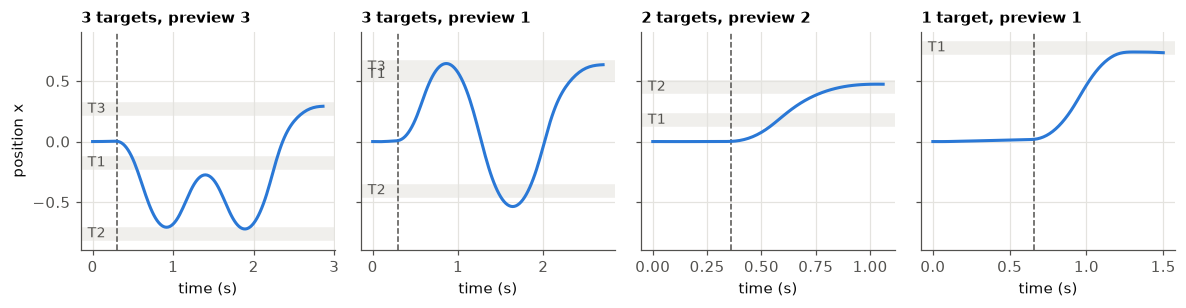

In [4]:
def show_trials(traj, idx):
    fig, axes = plt.subplots(1, len(idx), figsize=(11, 2.9), sharey=True)
    for ax, i in zip(axes, idx):
        alive = traj["alive"][:, i]
        t = np.flatnonzero(alive) * traj["dt"]
        for k in range(traj["n_targets"][i]):
            tg = traj["targets0"][i, k]
            ax.axhspan(tg - 0.05, tg + 0.05, color=BAND, zorder=0)
            ax.text(0.01, tg, f" T{k + 1}", transform=ax.get_yaxis_transform(),
                    va="center", color=INK_SOFT, fontsize=9)
        ax.axvline(traj["go_step"][i] * traj["dt"], color=INK_SOFT, ls="--", lw=1)
        ax.plot(t, traj["x"][alive, i], color=BLUE)
        n_tg = traj["n_targets"][i]
        ax.set_title(f"{n_tg} target{'s' if n_tg > 1 else ''}, preview {traj['preview'][i]}", fontsize=10)
        ax.set_xlabel("time (s)")
    axes[0].set_ylabel("position x")
    plt.tight_layout()

n, h = rand["n_targets"], rand["preview"]
pick = [np.flatnonzero((n == 3) & (h == 3))[0], np.flatnonzero((n == 3) & (h == 1))[0],
        np.flatnonzero(n == 2)[0], np.flatnonzero(n == 1)[0]]
show_trials(rand, pick)

## 3 · The co-articulation experiment

**The design** (`probes.preview_probe`). T1 is fixed at +0.45 (and, separately, −0.45).
T2 takes 25 positions between −0.9 and +0.9, skipping any too close to T1 or the start.
Every trial is run twice, once with **T2 visible** (preview 2) and once with **T2 hidden**
until T1 is hit (preview 1). Same agent, same physics, same targets: the only difference
is whether the agent can see where it goes next.

In [5]:
spec, design = probes.preview_probe(pcfg)
traj = probes.rollout(agent, obs_rms, pcfg, spec, n_trials=len(design["t1"]), seed=7)
print(len(design["t1"]), "trials")
pd.DataFrame(design).head(4)

72 trials


,t1,t2,preview,direction
0,0.45,-0.900,2,1.0
1,0.45,-0.900,1,1.0
2,0.45,-0.825,2,1.0
3,0.45,-0.825,1,1.0


**Look first, then measure.** Velocity from the go cue, for the rightward reaches, coloured
by where T2 is. `d_next` is T2's position relative to T1, signed so that + means T2 lies
*beyond* T1 (keep going) and − means *behind* it (turn back). Dots mark the moment the
mass first enters T1's band.

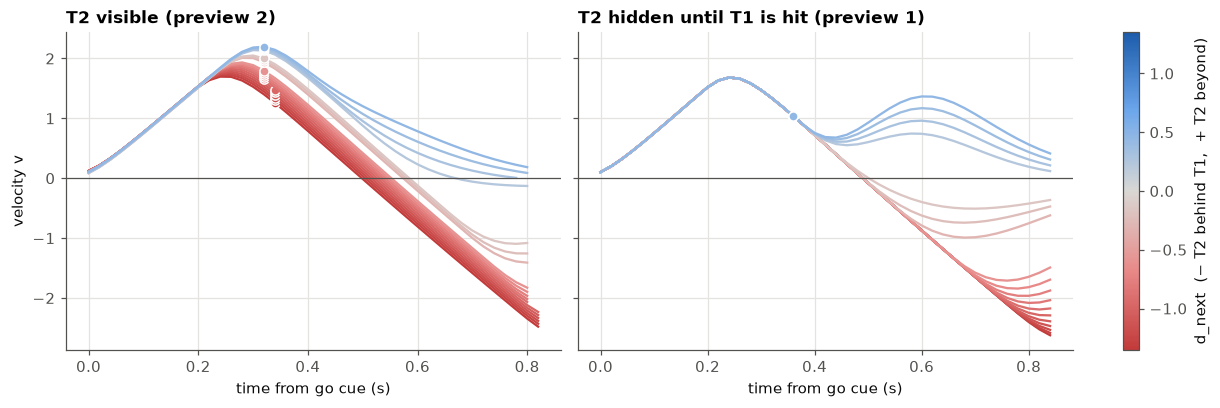

In [6]:
cmap = LinearSegmentedColormap.from_list("diverging", DIVERGING)
d_next = (design["t2"] - design["t1"]) * np.sign(design["t1"])
norm = Normalize(-1.35, 1.35)                      # symmetric, so d_next = 0 is grey

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, constrained_layout=True)
for ax, level in zip(axes, [2, 1]):
    for i in np.flatnonzero((design["direction"] == 1) & (design["preview"] == level)):
        go, entry = traj["go_step"][i], traj["entry_step"][i, 0]
        stop = min(entry + 25, np.flatnonzero(traj["alive"][:, i])[-1])
        color = cmap(norm(d_next[i]))
        ax.plot((np.arange(go, stop) - go) * traj["dt"], traj["v"][go:stop, i], color=color, lw=1.5)
        ax.plot((entry - go) * traj["dt"], traj["v"][entry, i], "o", color=color, ms=6, mec="white")
    ax.axhline(0, color=INK_SOFT, lw=0.8)
    ax.set_title("T2 visible (preview 2)" if level == 2 else "T2 hidden until T1 is hit (preview 1)")
    ax.set_xlabel("time from go cue (s)")
axes[0].set_ylabel("velocity v")
_ = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes,
                 label="d_next  (− T2 behind T1,  + T2 beyond)")

**Reading it.** With T2 visible, the reaches start out alike and fan out by T2 about
0.2 s after the go cue, well before T1 is reached. When T2 lies beyond T1 (blue) the agent
is still moving fast as it crosses T1; when T2 is behind (red) it arrives slower, already
preparing to turn. With T2 hidden, all 18 trials are **exactly identical** up to the moment
T1 is hit (the single dot), because the agent cannot know T2 and noise is off. Only after
that dot does T2 appear, and the traces split. That is the whole result in one picture.

Notice too that most trials are red. With T1 at 0.45 and T2 anywhere in ±0.9, T2 is more
often behind T1 than beyond it. That imbalance comes back in section 4.

The **co-articulation index (CI)** turns the picture into a number:

```
v_out   = velocity when first entering T1's band × sign(T1)     (+ = still moving onward)
d_next  = (T2 − T1) × sign(T1)                                   (+ = T2 lies beyond T1)
CI      = slope of v_out against d_next
```

Three details matter:

- **Folding by sign(T1)** lets leftward and rightward reaches share one axis.
- **Fit within direction.** The two directions are demeaned separately before fitting,
  because the learned policy is not mirror-symmetric (a fixed-effects regression).
- **First entry, not acquisition.** With a dwell requirement (`stop_at_targets`), velocity
  at acquisition is ~0 by construction; entry is the moment the mass passes through.

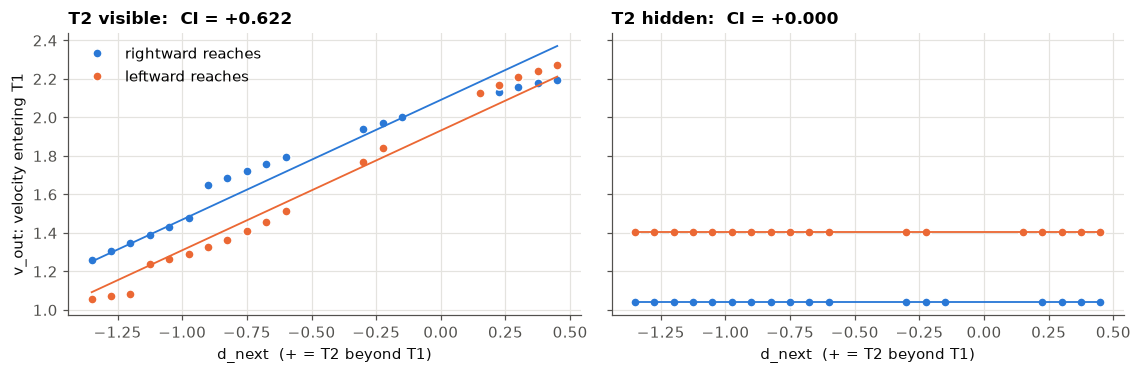

In [7]:
co = metrics.co_articulation_by_preview(traj, design)
on, off = co["preview_on"], co["preview_off"]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5), sharey=True)
for ax, (key, level) in zip(axes, [("preview_on", 2), ("preview_off", 1)]):
    res = co[key]
    direction = design["direction"][design["preview"] == level][res["trials"]]
    for d, color, name in [(1, BLUE, "rightward reaches"), (-1, ORANGE, "leftward reaches")]:
        m = direction == d
        x, y = res["d_next"][m], res["v_out"][m]
        ax.plot(x, y, "o", color=color, ms=6, mec="white", label=name)
        xs = np.linspace(x.min(), x.max(), 2)
        ax.plot(xs, y.mean() + res["ci"] * (xs - x.mean()), color=color, lw=1.2)
    ax.set_title(f"{'T2 visible' if level == 2 else 'T2 hidden'}:  CI = {res['ci']:+.3f}")
    ax.set_xlabel("d_next  (+ = T2 beyond T1)")
axes[0].set_ylabel("v_out: velocity entering T1")
axes[0].legend(loc="upper left")
plt.tight_layout()

CI > 0 means the agent carries more speed through T1 the further onward T2 is: it is
co-articulating. With T2 hidden the slope is **exactly 0**. That is not a small effect;
it is a hard null, because the trajectories are identical. It certifies that the visible
slope is caused by T2 *information*, not by target geometry or the estimator.

**Where it lives:** `co_articulation` in [`seqreach/metrics.py`](../seqreach/metrics.py).

## 4 · The checks that decide whether a CI means anything

A slope always comes with a p-value. These checks decide whether it deserves to be read.
They are all computed already:

In [8]:
td = metrics.t2_dependence_by_preview(traj, design)
checks = {
    "CI (T2 visible)":                  on["ci"],
    "  standard error":                 on["ci_se"],
    "  p-value":                        on["ci_p"],
    "CI (T2 hidden): must be exactly 0": off["ci"],
    "trials used (of 36)":              on["n"],
    "r: how linear the relation is":    on["ci_r"],
    "CI, rightward reaches only":       on["by_group"][1.0],
    "CI, leftward reaches only":        on["by_group"][-1.0],
    "directions agree in sign":         on["dir_agree"],
    "CI on a window symmetric about 0": on["ci_balanced"],
    "T2 velocity spread (visible)":     td["preview_on"]["v_spread_rms"],
    "T2 velocity spread (hidden)":      td["preview_off"]["v_spread_rms"],
}
# 3 significant digits, so tiny numbers (p-values, the ~1e-16 control) stay visible
pd.Series({k: f"{v:.3g}" if isinstance(v, float) else v for k, v in checks.items()}).to_frame("baseline_s1")

,baseline_s1
CI (T2 visible),0.622
standard error,0.0216
p-value,1.77e-25
CI (T2 hidden): must be exactly 0,0
trials used (of 36),36
r: how linear the relation is,0.98
"CI, rightward reaches only",0.526
"CI, leftward reaches only",0.713
directions agree in sign,True
CI on a window symmetric about 0,0.662


| check | what it guards against |
|---|---|
| **competence ≥ 0.90** (section 2) | an index describing a movement the agent does not make |
| **trials used = 36** | "probe attrition": if the agent fails to reach T1 on some trials, the slope is fit to a biased subset |
| **hidden CI = 0 exactly** | a broken pipeline. Any non-zero value means noise was left on, the policy was sampled, or T2 leaked into the observation |
| **r** | a significant slope that explains little variance (r = 0.3 explains 9%) is not the same result as r = 0.98 |
| **directions agree** | if rightward and leftward reaches have opposite slopes, the pooled slope is not a signed effect |
| **symmetric-window CI ≈ CI** | T1 at ±0.45 and T2 in ±0.9 means `d_next` spans −1.35 to +0.45, so most trials are on the "turn back" side. A big gap means the relation is curved and one slope misdescribes it |
| **T2 velocity spread** | a sign-free measure: *how much* does the reach to T1 vary with T2 at all? Hidden it is ~1e-16, which is floating-point zero |

The last one matters when CI is near zero. A CI of 0 with a large velocity spread means the
agent *does* use T2, just not in the monotonic "faster when T2 is onward" way, which is a
different claim from "the agent ignores T2". (Design doc §8.2–8.3.)

## 5 · Compare agents, and why one seed is not a result

The same measurements, packed into one function and run on four agents:

- `baseline_s1`: the default task;
- `gamma097_sparse_s2`: discount 0.97, shaping off (axis C7);
- `stop_at_targets_s1`: must rest 0.5 s at each target (axis C1, Case A);
- `stop_at_targets_s3`: the same arm, a seed that failed to learn.

In [9]:
def measure(run):
    agent, obs_rms, cfg = load_agent(RUNS / run)
    pcfg = probes.probe_config(cfg)
    o = probes.outcome_breakdown(probes.rollout(agent, obs_rms, pcfg, {}, n_trials=512, seed=123))
    spec, design = probes.preview_probe(pcfg)
    traj = probes.rollout(agent, obs_rms, pcfg, spec, n_trials=len(design["t1"]), seed=7)
    on = metrics.co_articulation_by_preview(traj, design)["preview_on"]
    td = metrics.t2_dependence_by_preview(traj, design)["preview_on"]
    return {"success": o["success_rate"], "multi-target success": o["success_multi_target"],
            "timeouts": o["timeout_rate"], "touched wall": o["wall_contact_rate"],
            "competent": o["competent"], "CI": on["ci"], "r": on["ci_r"],
            "directions agree": on["dir_agree"], "T2 velocity spread": td["v_spread_rms"]}

runs = ["baseline_s1", "gamma097_sparse_s2", "stop_at_targets_s1", "stop_at_targets_s3"]
comparison = pd.DataFrame({run: measure(run) for run in runs}).T
comparison.style.format(precision=3)

,success,multi-target success,timeouts,touched wall,competent,CI,r,directions agree,T2 velocity spread
baseline_s1,0.994,0.992,0.006,0.000,True,0.622,0.980,True,0.103
gamma097_sparse_s2,1.000,1.000,0.000,0.318,True,0.194,0.850,True,0.035
stop_at_targets_s1,1.000,1.000,0.000,0.000,True,-0.233,-0.926,True,0.068
stop_at_targets_s3,0.215,0.000,0.785,0.016,False,0.117,0.883,True,0.025


**Reading it.**

- **`stop_at_targets_s3` is the cautionary tale.** Its CI is positive, linear, and
  consistent across directions, and it looks like a clean result. But the agent fails every
  multi-target trial by timeout. The index describes a movement it does not complete. The
  competence gate is the only thing standing between this number and a paper.
- **`stop_at_targets_s1`** learned the task and shows a *negative* CI (results doc §6).
- **`gamma097_sparse_s2`** is competent, with a smaller CI and a smaller T2 spread than
  baseline, which is what a shorter horizon predicts (lesson 3). It also touches the wall on
  a sizeable fraction of trials while still succeeding. Worth following up when you analyse
  the γ arm; it is not yet in the results doc.
- Each row is **one seed**. This is a demonstration of the pipeline, not a finding.

Here is why one seed is not enough: the baseline's CI across its 8 seeds, read from the
`results.json` files that `analyze.py` wrote.

per seed: [0.622 0.606 0.238 0.614 0.472 0.437 0.472 0.651]


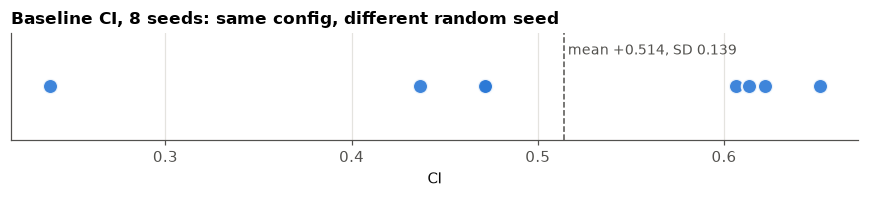

In [10]:
cis = [json.loads((RUNS / f"baseline_s{s}" / "analysis" / "results.json").read_text())
       ["coarticulation"]["ci"] for s in range(1, 9)]

fig, ax = plt.subplots(figsize=(8, 1.9))
ax.plot(cis, np.zeros(8), "o", color=BLUE, ms=10, mec="white", mew=1.5, alpha=0.9)
ax.axvline(np.mean(cis), color=INK_SOFT, lw=1, ls="--")
ax.text(np.mean(cis), 0.6, f" mean {np.mean(cis):+.3f}, SD {np.std(cis, ddof=1):.3f}",
        color=INK_SOFT, fontsize=9)
ax.set_ylim(-1, 1)
ax.set_yticks([])
ax.grid(axis="y", visible=False)
ax.set_xlabel("CI")
ax.set_title("Baseline CI, 8 seeds: same config, different random seed")
plt.tight_layout()
print("per seed:", np.round(cis, 3))

Every seed is positive, but the values range widely. The spread across seeds is several
times the standard error of any single run, so **report a distribution over ≥ 8 seeds,
compare only competent agents, and compare conditions within one campaign.**

## 6 · The full battery: `scripts/analyze.py`

Everything above, plus three more measurements, runs from one command:

```bash
.conda/bin/python 1D/scripts/analyze.py --run 1D/runs/baseline_s1
```

| section | measures | design doc |
|---|---|---|
| competence | section 2 of this lesson, plus the "budget-limited" flag | §8.1 |
| co-articulation | sections 3–4, plus how early the T2 trajectories diverge | §8.2–8.3 |
| reaction time | go cue → movement onset, as a function of hold duration | §8.4 |
| target jumps | how the ongoing reach changes when T1 or T2 moves mid-movement | §8.4 |
| preparatory state | GRU state during the hold: can upcoming movement parameters be decoded, and is preparation "output-null" | §8.4 |

It writes `runs/<run>/analysis/results.json` and figures. For example, the reaction-time
result for this agent:

In [11]:
res = json.loads((RUNS / "baseline_s1" / "analysis" / "results.json").read_text())
print("sections:", [k for k, v in res.items() if isinstance(v, dict)])
pd.DataFrame(res["reaction_time"]["by_delay"]).round(4)

sections: ['success_by_n_targets', 'coarticulation', 'divergence', 'reaction_time', 'jump', 'preparatory']


,delay_s,n,rt_mean,rt_sem
0,0.10,40,0.0205,0.0005
1,0.24,40,0.0120,0.0016
2,0.50,40,0.0095,0.0016
3,0.74,40,0.0095,0.0016
4,1.00,40,0.0110,0.0016


Reaction time falls as the hold gets longer, the classic preparation signature, and
nothing trained it. But look at the scale: every value is 0–20 ms, which is one simulation
step. With no sensory delay (`plant.sensory_delay = 0`) the effect has almost no room to
show, so treat it as a direction, not a size (design doc §12, point 6).

## 7 · Your own experiment

The probes above are fixed recipes. For your own questions, build a trial list with
`TrialList` and run the frozen agent through it, as you would design a behavioural session.

Take idea 7 from your notes (`doc/1D_experiments_human_thoughts.md`), a Churchland-style
design. Put T1 close to the start, so the first reach is nearly the same in every trial;
sweep T2; and ask whether the reach to T1 already reflects T2. Each trial also runs with T2
hidden, as the control.

In [12]:
trials = TrialList(pcfg)
for t2 in np.linspace(-0.9, 0.9, 19):
    if abs(t2 - 0.2) < pcfg.task.min_separation:
        continue                                        # too close to T1
    for preview in (2, 1):                              # T2 visible, then hidden: the control
        trials.add([0.2, t2], preview=preview, delay_steps=25,
                   factors={"t2": t2, "t2_visible": preview == 2})
near = trials.build(name="near_t1")
print(near.n_trials, "trials")

traj_near = probes.rollout(agent, obs_rms, pcfg, near.spec, n_trials=near.n_trials, seed=0)
table = dataset.trial_frame(traj_near, near, "baseline_s1")
table[["t2", "t2_visible", "success", "T1_entry_ms", "T1_v_entry", "T1_peak_v"]].head(6)

32 trials


,t2,t2_visible,success,T1_entry_ms,T1_v_entry,T1_peak_v
0,-0.9,True,True,720.0,0.878906,0.978397
1,-0.9,False,True,720.0,0.877817,1.024651
2,-0.8,True,True,720.0,0.982303,1.066486
3,-0.8,False,True,720.0,0.877817,1.024651
4,-0.7,True,True,700.0,1.135722,1.135722
5,-0.7,False,True,720.0,0.877817,1.024651


`dataset.trial_frame` gives one row per trial: the design (your `factors` become columns),
the outcome, and per-target events such as entry and acquisition times, velocity at entry,
and peak velocity. `dataset.timeseries_frame` gives one row per trial per time step. The
columns are documented in [`data/README.md`](../../data/README.md).

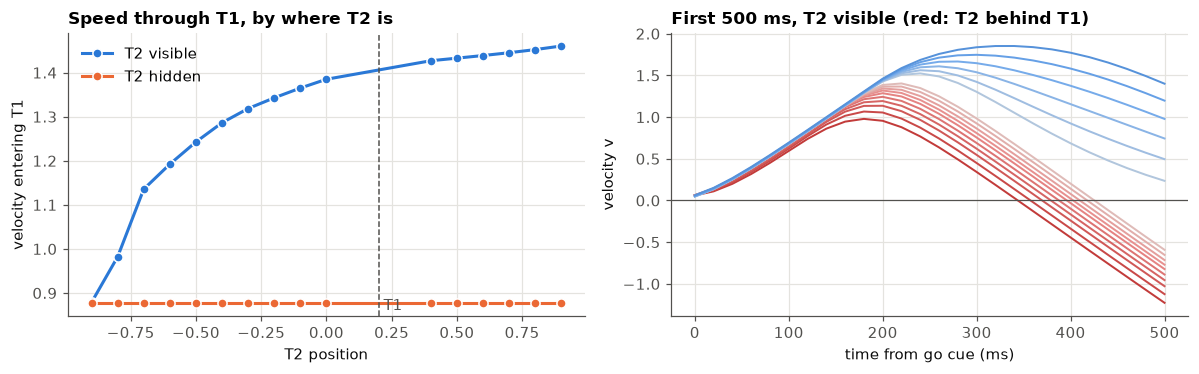

In [13]:
fig, (ax_t, ax_v) = plt.subplots(1, 2, figsize=(11, 3.5))

for vis, color, name in [(True, BLUE, "T2 visible"), (False, ORANGE, "T2 hidden")]:
    s = table[table.t2_visible == vis]
    ax_t.plot(s.t2, s.T1_v_entry, "o-", color=color, ms=6, mec="white", label=name)
ax_t.axvline(0.2, color=INK_SOFT, lw=1, ls="--")
ax_t.text(0.2, 0.02, " T1", transform=ax_t.get_xaxis_transform(), color=INK_SOFT)
ax_t.set_xlabel("T2 position")
ax_t.set_ylabel("velocity entering T1")
ax_t.set_title("Speed through T1, by where T2 is")
ax_t.legend()

ts = dataset.timeseries_frame(traj_near, near, "baseline_s1")
vis_ts = ts[(ts.t2_visible == True) & (ts.t_from_go_ms.between(0, 500))]
tcmap = LinearSegmentedColormap.from_list("diverging", DIVERGING)
tnorm = Normalize(-1.1, 1.1)
for t2, g in vis_ts.groupby("t2"):
    ax_v.plot(g.t_from_go_ms, g.v, color=tcmap(tnorm(t2 - 0.2)), lw=1.3)
ax_v.axhline(0, color=INK_SOFT, lw=0.8)
ax_v.set_xlabel("time from go cue (ms)")
ax_v.set_ylabel("velocity v")
ax_v.set_title("First 500 ms, T2 visible (red: T2 behind T1)")
plt.tight_layout()

Even with T1 only 0.2 away, the reach to it depends on T2, and with T2 hidden it does not.
That is the kind of result your idea 7 is after. From here the questions in your notes
(when do kinematic parameters become decodable from the GRU state, and in which subspace)
use `traj_near["h"]`: the hidden state, shaped (time, trial, 128).

**To make an experiment permanent**, add it to
[`seqreach/experiments.py`](../seqreach/experiments.py) with the `@experiment` decorator.
Then anyone can run it on any agent from the terminal, and the data land in `data/` as CSVs
with a metadata file:

```python
@experiment("near_t1", "T1 close to the start, T2 swept, visible vs hidden.")
def near_t1(cfg, *, t1: float = 0.2, n_t2: int = 19, delay_steps: int = 25):
    trials = TrialList(cfg)
    for t2 in np.linspace(-0.9, 0.9, n_t2):
        if abs(t2 - t1) < cfg.task.min_separation:
            continue
        for preview in (2, 1):
            trials.add([t1, t2], preview=preview, delay_steps=delay_steps,
                       factors={"t2": t2, "t2_visible": preview == 2})
    return trials.build()
```

```bash
.conda/bin/python 1D/scripts/run_experiment.py --list
.conda/bin/python 1D/scripts/run_experiment.py --run 1D/runs/baseline_s1 --exp near_t1
.conda/bin/python 1D/scripts/run_experiment.py --run 1D/runs/baseline_s1 --exp near_t1 --param t1=0.3 --save-hidden
```

## 8 · Cheat sheet

Run from the repo root. Always pass `--wandb` when training.

| I want to… | command |
|---|---|
| train one agent | `.conda/bin/python 1D/scripts/train.py --name NAME --timesteps 3000000 --seed 1 --wandb --set key=value …` |
| train every ablation arm for one seed | `.conda/bin/python 1D/scripts/run_ablations.py --seed 1 --timesteps 3000000 --parallel 9 --threads 1 --no-video --wandb` (add `--only ARM …` for a subset) |
| … for 8 seeds | wrap the line above in `for s in 1 2 3 4 5 6 7 8; do … --seed $s; done` |
| add a new arm | add an entry to `ABLATIONS` at the top of `1D/scripts/run_ablations.py` |
| analyse one agent | `.conda/bin/python 1D/scripts/analyze.py --run 1D/runs/NAME_s1` |
| re-summarise the grid for one seed | `.conda/bin/python 1D/scripts/run_ablations.py --analyze-only --seed 1` |
| watch an agent | `.conda/bin/python 1D/scripts/make_video.py --run 1D/runs/NAME_s1` |
| export an experiment's data | `.conda/bin/python 1D/scripts/run_experiment.py --run 1D/runs/NAME_s1 --exp preview_sweep` |
| run the tests | `.conda/bin/python -m pytest 1D/tests -q` |

**Where to read next:** [`doc/1D_task_and_design.md`](../../doc/1D_task_and_design.md), which
has the full argument (§2), every measurement (§8) and the lessons learned (§11.2).
[`doc/1D_results.md`](../../doc/1D_results.md) has what has been measured so far.

## Check yourself

**1.** Why do probes run with motor noise off and the policy mean instead of samples?

<details><summary>Answer</summary>

So identical trials give identical movements. Then any difference between conditions is
caused by the condition, and the T2-hidden control is exactly zero rather than
"approximately zero".
</details>

**2.** An agent scores 0.95 on one-target trials and 0.05 on multi-target trials. Its CI is
+0.4 with p < 10⁻⁶. What do you report about lookahead?

<details><summary>Answer</summary>

Nothing. It is below the competence floor and has learned a single reach, so there is no
second movement for lookahead to plan. Report it as a failed arm, and check the time budget.
</details>

**3.** The T2-hidden CI comes out at 0.03 instead of 0. What does that tell you?

<details><summary>Answer</summary>

Something in the pipeline is broken: noise left on, a sampled policy, or T2 leaking into the
observation. With T2 hidden the trajectories must be bit-identical.
</details>

**4.** Rightward CI is +0.5, leftward is −0.3, and the pooled CI is +0.1 with p = 0.01. What
do you report?

<details><summary>Answer</summary>

Not a signed effect, because the directions disagree. Report the sign-free T2 velocity
spread instead, and look at the two directions separately.
</details>

**5.** Why measure velocity at first *entry* into T1 rather than when T1 is counted as hit?

<details><summary>Answer</summary>

With a dwell requirement, T1 is only counted after the mass has rested there, so velocity
at that moment is ~0 by construction. That would manufacture the "no lookahead" prediction
in exactly the condition meant to test it.
</details>

## Summary

- **Measure frozen agents, noise off, policy mean**, so conditions differ only by the
  manipulation.
- **Competence first.** Split success by sequence length and sort failures by cause. Below
  0.90, no index is reported.
- **The co-articulation experiment**: fix T1, sweep T2, visible vs hidden. CI is the slope
  of speed-through-T1 on where T2 is; the hidden control is exactly 0.
- **Read CI with its checks**: trials used, r, direction agreement, the symmetric window,
  and the sign-free T2 spread.
- **8 seeds per condition, competent agents only.**
- **Your own experiments** are a `TrialList`, run with `probes.rollout`, turned into tables
  with `dataset.trial_frame` / `timeseries_frame`, and made permanent in `experiments.py`.